# SIT744 Assignment 4 — Student Submission Template

This template is for organising your submission and reporting results consistently. It is **not** a worked solution. Replace all bracketed text and add your own implementation code where indicated.


## Student and submission details

- **Student name:** [Replace]
- **Student ID:** [Replace]
- **Unit code:** SIT744
- **Assignment:** Assignment 4
- **Date:** [Replace]


## Notes

- Keep answers short and to the point.
- Keep code outputs clean; remove excessive logs before exporting to PDF.
- Use the fixed assignment protocol from the brief: `distilgpt2`, the same tokenizer, the required three text files, perplexity, and the fixed generation prompt.
- Use one coherent pipeline across Tasks 1--3.
- The purpose of this template is to make reporting consistent for marking. You are responsible for writing and explaining your own code.


## Fixed protocol summary

| Item | Required setting |
|---|---|
| Base model | `distilgpt2` |
| Tokenizer | tokenizer associated with `distilgpt2` |
| Training text | `undrip_train.txt` |
| Validation text | `undrip_val.txt` |
| Held-out related evaluation text | `economic_test.txt` |
| Required metric | perplexity |
| Generation prompt | `Economic self-determination for First Nations peoples requires` |
| Full fine-tuning | use the fixed configuration from the assignment brief/starter guidance |
| LoRA | use the fixed LoRA configuration from the assignment brief/starter guidance |


## Fixed configuration values for required results

Use the following configuration values for the required Task 2 and Task 3 comparison. These cells specify the controlled protocol only; they do **not** provide the implementation. Do not change these values for the main results reported in the master results table.


In [1]:
# Fixed configuration values for Assignment 4.
# These are provided so all students report results under the same protocol.

BASE_MODEL = "distilgpt2"

TEXT_FILES = {
    "train": "undrip_train.txt",
    "validation": "undrip_val.txt",
    "test": "economic_test.txt",
}

GENERATION_PROMPT = "Economic self-determination for First Nations peoples requires"

TOKENISATION_CONFIG = {
    "block_size": 128,
}

# Settings for perplexity evaluation.
# These are not Hugging Face TrainingArguments.
PERPLEXITY_MAX_LENGTH = 128
PERPLEXITY_STRIDE = 128

GENERATION_CONFIG = {
    "max_new_tokens": 80,
    "do_sample": False,
}


FULL_FINE_TUNING_CONFIG = {
    "output_dir": "./distilgpt2-full-finetuned",
    "num_train_epochs": 1,
    "learning_rate": 5e-5,
    "per_device_train_batch_size": 2,
    "per_device_eval_batch_size": 2,
    "weight_decay": 0.01,
    "logging_steps": 20,
    "save_strategy": "no",
    "report_to": "none",
}

LORA_CONFIG = {
    "r": 8,
    "lora_alpha": 16,
    "lora_dropout": 0.05,
    "target_modules": ["c_attn"],
    "bias": "none",
    "task_type": "CAUSAL_LM",
}

# LORA_CONFIG controls the LoRA adapter itself: rank, scaling, dropout,
# and target modules.

# LORA_TRAINING_CONFIG controls how the LoRA adapter is trained. 
LORA_TRAINING_CONFIG = {
    "output_dir": "./distilgpt2-lora-finetuned",
    "num_train_epochs": 1,
    "learning_rate": 1e-4,
    "per_device_train_batch_size": 2,
    "per_device_eval_batch_size": 2,
    "weight_decay": 0.01,
    "logging_steps": 20,
    "save_strategy": "no",
    "report_to": "none",
}


In [2]:
# Optional setup for Colab or a fresh environment.
# Uncomment and run this cell if the required packages are not installed.
# !pip install transformers datasets accelerate peft python-docx pypdf matplotlib pandas

# Silence download/loading progress bars so the exported PDF stays clean.
import os
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
import transformers
transformers.utils.logging.disable_progress_bar()

## Required tokenizer and model setup

In [3]:
from transformers import AutoTokenizer, AutoModelForCausalLM, TrainingArguments

tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL)

# GPT-style tokenizers such as distilgpt2 do not define a separate padding token by default.
# Use the EOS token as the padding token so that batched training/evaluation can run.
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

pretrained_model = AutoModelForCausalLM.from_pretrained(BASE_MODEL)
pretrained_model.resize_token_embeddings(len(tokenizer))
pretrained_model.config.pad_token_id = tokenizer.pad_token_id

## Environment and imports

In [4]:
# Add or modify imports as needed for your implementation.
# Keep this cell concise.

import os
import re
import math
import time
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

import docx                      # python-docx: Word extraction
import pypdf                     # PDF extraction
import transformers
from datasets import Dataset
from transformers import Trainer, default_data_collator
from peft import LoraConfig, get_peft_model

# Keep exported outputs clean (no long-sequence / deprecation chatter).
transformers.logging.set_verbosity_error()
warnings.filterwarnings("ignore")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"torch {torch.__version__} | transformers {transformers.__version__} | device: {DEVICE}")

torch 2.14.1+cpu | transformers 5.19.0 | device: cpu


## Reproducibility

In [5]:
# Reproducibility
# This reduces run-to-run variation in data shuffling, model initialisation, and generation.
# Exact reproducibility is still not guaranteed on all GPU/CUDA setups.

import random
import numpy as np
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

print(f"Seed set to {SEED}")


Seed set to 42


# Task 1 Data preparation and pretrained baseline (25%)

In this task, prepare the three required text files and establish the pretrained baseline.


##  Source documents and extraction method

**Fine-tuning source document:** Joint Standing Committee on Aboriginal and Torres Strait Islander Affairs, *Inquiry into the application of the United Nations Declaration on the Rights of Indigenous Peoples in Australia*, November 2023. This is the Word (.docx) version from the APH report page, saved as `source_documents/undrip_report.docx`.

**Held-out related evaluation source document:** Joint Standing Committee on Aboriginal and Torres Strait Islander Affairs, *Inquiry into economic self-determination and opportunities for First Nations Australians*, November 2024. Only a PDF version is offered; it is saved as `source_documents/economic_report.pdf`.

**Extraction method**  
The UNDRIP Word file was read paragraph by paragraph with `python-docx`, skipping cover, copyright and table-of-contents paragraphs identified by their Word style. Footnotes sit outside the paragraph stream, so they are not extracted. The Economic PDF was converted page by page with `pypdf`, dropping standalone page-number lines and dotted contents-leader lines and replacing the PDF bullet glyph with "-". Both raw texts then went through the brief's `clean_text` (strip lines, remove empty lines), and the UNDRIP text was split 80/20 by characters with `split_text`.

In [6]:
# Data preparation code goes here.
# Creates exactly: undrip_train.txt, undrip_val.txt, economic_test.txt (80/20 UNDRIP split).

# 1. Source documents. parlinfo.aph.gov.au sits behind an Azure WAF JavaScript challenge,
#    so scripted downloads are refused (HTTP 403). Download both files in a browser from the
#    URLs below and save them in ./source_documents/ under the names shown.
SOURCE_DIR = Path("source_documents")
SOURCES = {
    SOURCE_DIR / "undrip_report.docx": (
        "https://parlinfo.aph.gov.au/parlInfo/download/committees/reportjnt/RB000083/toc_word/"
        "InquiryintotheapplicationoftheUnitedNationsDeclarationontheRightsofIndigenousPeoplesinAustralia.docx"),
    SOURCE_DIR / "economic_report.pdf": (
        "https://parlinfo.aph.gov.au/parlInfo/download/committees/reportjnt/RB000393/toc_pdf/"
        "Inquiryintoeconomicself-determinationandopportunitiesforFirstNationsAustralians.pdf"),
}
for path, url in SOURCES.items():
    if not path.exists():
        raise FileNotFoundError(f"Download {url}\n  and save it as {path}")
    print(f"{path}  ({path.stat().st_size / 1e6:.2f} MB)")

# 2. Extract plain text.
# Word: one line per paragraph. Cover, copyright and table-of-contents paragraphs are
# identified by their Word style names and skipped (website/boilerplate, not report content).
SKIP_DOCX_STYLES = {"title", "subtitle 2", "normal narrow", "copyright", "copyright bullets", "toc heading"}

def extract_docx_text(path):
    lines = []
    for paragraph in docx.Document(path).paragraphs:
        style = paragraph.style.name.lower()
        if style in SKIP_DOCX_STYLES or style.startswith("toc "):
            continue
        lines.append(paragraph.text)
    return "\n".join(lines)

# PDF: one line per visual line. Drop standalone page numbers (running footers) and dotted
# table-of-contents leader lines; replace the Symbol-font bullet glyph with "-".
PAGE_NUMBER_LINE = re.compile(r"^\s*(\d{1,3}|[ivxlc]{1,6})\s*$", re.IGNORECASE)
TOC_LEADER_LINE = re.compile(r"\.{5,}\s*(\d{1,3}|[ivxlc]{1,6})\s*$", re.IGNORECASE)

def extract_pdf_text(path):
    lines = []
    for page in pypdf.PdfReader(path).pages:
        for line in (page.extract_text() or "").splitlines():
            if PAGE_NUMBER_LINE.match(line) or TOC_LEADER_LINE.search(line):
                continue
            lines.append(line.replace("\uf0b7", "-"))
    return "\n".join(lines)

Path("source_documents/undrip_raw.txt").write_text(extract_docx_text(SOURCE_DIR / "undrip_report.docx"), encoding="utf-8")
Path("source_documents/economic_raw.txt").write_text(extract_pdf_text(SOURCE_DIR / "economic_report.pdf"), encoding="utf-8")

# 3-7. Required preprocessing protocol (the brief's scaffold, unchanged).
def clean_text(text):
    lines = text.splitlines()
    lines = [line.strip() for line in lines]
    lines = [line for line in lines if len(line) > 0]
    return "\n".join(lines)

def split_text(text, train_ratio=0.8):
    split_index = int(len(text) * train_ratio)
    return text[:split_index], text[split_index:]

undrip_raw = Path("source_documents/undrip_raw.txt").read_text(encoding="utf-8")
economic_raw = Path("source_documents/economic_raw.txt").read_text(encoding="utf-8")

undrip_clean = clean_text(undrip_raw)
economic_clean = clean_text(economic_raw)
undrip_train, undrip_val = split_text(undrip_clean, train_ratio=0.8)

Path(TEXT_FILES["train"]).write_text(undrip_train, encoding="utf-8")
Path(TEXT_FILES["validation"]).write_text(undrip_val, encoding="utf-8")
Path(TEXT_FILES["test"]).write_text(economic_clean, encoding="utf-8")

for name in TEXT_FILES.values():
    print(f"wrote {name}")

source_documents/undrip_report.docx  (0.79 MB)
source_documents/economic_report.pdf  (1.25 MB)


wrote undrip_train.txt
wrote undrip_val.txt
wrote economic_test.txt


### Source-to-text example and remaining artefact

The cell below shows (a) one paragraph as stored in the UNDRIP Word file and how it appears in `undrip_train.txt`, and (b) one page fragment from the Economic PDF before and after extraction/cleaning.

In [7]:
# (a) Word paragraph -> plain text
source_paragraph = next(p for p in docx.Document(SOURCE_DIR / "undrip_report.docx").paragraphs
                        if p.text.startswith("Australia has been a signatory of UNDRIP"))
print(f"[Word paragraph, style='{source_paragraph.style.name}']\n{source_paragraph.text[:300]}\n")
position = undrip_train.find(source_paragraph.text[:60])
print(f"[undrip_train.txt, character {position}]\n{undrip_train[position:position + 300]}\n")

# (b) PDF page -> plain text: footnotes and hard line-wraps survive cleaning
pdf_page = pypdf.PdfReader(SOURCE_DIR / "economic_report.pdf").pages[40].extract_text()
print("[Economic PDF, page 41 (printed p. 17) - last 350 raw characters]")
print(pdf_page[-350:])
position = economic_clean.find("22 Kinya Lerrk Pty Ltd, Submission 94")
print("\n[economic_test.txt - same place]")
print(economic_clean[position - 200:position + 160])

[Word paragraph, style='Body Text Continued']
Australia has been a signatory of UNDRIP since 2009. The United Nations calls upon all signatories to UNDRIP to uphold the inherent human rights of Indigenous peoples and to implement these within their political and institutional frameworks, while preserving the integrity and unity of the Nation St

[undrip_train.txt, character 1009]
Australia has been a signatory of UNDRIP since 2009. The United Nations calls upon all signatories to UNDRIP to uphold the inherent human rights of Indigenous peoples and to implement these within their political and institutional frameworks, while preserving the integrity and unity of the Nation St

[Economic PDF, page 41 (printed p. 17) - last 350 raw characters]
e who are like-minded. I think educational programs, such as Melbourne 
Business School, are so helpful. They also build that network and support and 
opportunities.23 
 
22 Kinya Lerrk Pty Ltd, Submission 94, pages 1–2. 
23 Mrs Jasmine Kadic, Direc

**Example.** The Word paragraph above (style *Body Text Continued*) appears unchanged as one line of `undrip_train.txt` (character 1,009). Word extraction keeps paragraph boundaries and leaves out footnotes, which are stored separately in the .docx.

**Remaining artefact.** In the Economic PDF text, footnotes survive and are spliced into the body at every page break (`opportunities.23` is followed by `22 Kinya Lerrk Pty Ltd, Submission 94, pages 1–2.`). Also, every visual PDF line ends in a newline, so sentences break mid-clause (68 characters per line on average, compared with 241 in `undrip_train.txt`; Table 1). Some words are split by extraction (`Indi genous`, `indus tries`). A model trained on the Word-derived UNDRIP text never sees these patterns, so they can distort perplexity on `economic_test.txt`.

### 80/20 split boundary inspection

In [8]:
split_index = len(undrip_train)
print(f"Split at character {split_index:,} of {len(undrip_clean):,}")
print("...end of undrip_train.txt:  ", repr(undrip_train[-160:]))
print("...start of undrip_val.txt:  ", repr(undrip_val[:160]))

Split at character 320,449 of 400,562
...end of undrip_train.txt:   'ts from their families, cultures and spiritual connections due to incarceration is also a threat to First Peoples’ cultural rights. This denies our people acces'
...start of undrip_val.txt:   's to culture which also serves as a protective factor from recidivism.\nThe Western Australian Commissioner for Children and Young People highlighted this in the'


**A word-boundary issue is present.** The 80% character index (320,449) falls inside the word *access*. `undrip_train.txt` ends with `This denies our people acces` and `undrip_val.txt` starts with `s to culture which…`, so the split also cuts a sentence and a paragraph. **Why it matters:** training ends on a non-word, and the first validation window opens with an orphan `s` and no context, inflating its loss. One paragraph of Senator Thorpe's comments also spans both files (minor leakage). Over 15,425 scored tokens the effect is negligible, but a paragraph-boundary split would avoid it.

##  Data-preparation table

Table 1a. Required statistics. Token counts use the `distilgpt2` tokenizer on the whole file. Further statistics are in Table 1 below.

| File | Role | Character count | Approximate token count |
|---|---|---:|---:|
| `undrip_train.txt` | training text | 320,449 | 62,489 |
| `undrip_val.txt` | validation text | 80,113 | 15,547 |
| `economic_test.txt` | held-out related evaluation text | 439,603 | 97,708 |

**Notable difference.** `economic_test.txt` is longer than the whole UNDRIP report and much more fragmented. It has 6,374 lines averaging 68 characters (241 in the training file), 13.3% citation-style lines (0.1%), 2.8% digit characters (1.0%) and 1.54 tokens per word (1.30). These differences come from PDF versus Word extraction (line-wraps and footnotes kept) more than from topic. Note also that the final 20% of the UNDRIP report is not ordinary body text. `undrip_val.txt` holds the end of Senator Thorpe's additional comments, the submission and hearing lists, and the full text of the UN Declaration (Appendixes A–D).

In [9]:
# Code used to compute character counts, approximate token counts and other basic statistics.
CITATION_LINE = re.compile(r"(Submission \d+|Committee Hansard|Hansard|\bpp?\. ?\d+|https?://)")

def text_statistics(path):
    text = Path(path).read_text(encoding="utf-8")
    lines = text.splitlines()
    n_tokens = len(tokenizer(text)["input_ids"])
    n_words = len(text.split())
    return {
        "File": path,
        "Characters": len(text),
        "Approx. tokens (distilgpt2)": n_tokens,
        "Words": n_words,
        "Tokens per word": round(n_tokens / n_words, 3),
        "Lines": len(lines),
        "Mean chars per line": round(np.mean([len(l) for l in lines]), 1),
        "Digit chars (%)": round(100 * sum(ch.isdigit() for ch in text) / len(text), 2),
        "Citation-style lines (%)": round(100 * np.mean([bool(CITATION_LINE.search(l)) for l in lines]), 1),
    }

data_stats = pd.DataFrame([text_statistics(p) for p in TEXT_FILES.values()]).set_index("File")
print("Table 1. Statistics of the three prepared text files")
data_stats

Table 1. Statistics of the three prepared text files


,Characters,Approx. tokens (distilgpt2),Words,Tokens per word,Lines,Mean chars per line,Digit chars (%),Citation-style lines (%)
File,,,,,,,,
undrip_train.txt,320449,62489,48203,1.296,1324,241.0,0.99,0.1
undrip_val.txt,80113,15547,11685,1.331,620,128.2,1.08,0.0
economic_test.txt,439603,97708,63459,1.540,6374,68.0,2.78,13.3


##  Pretrained baseline evaluation

Evaluate pretrained `distilgpt2` on `undrip_val.txt` and `economic_test.txt`. Complete only the pretrained row of the master results table at this stage.


In [10]:
# Pretrained baseline loading and perplexity evaluation code goes here.
# Non-overlapping 128-token windows (max_length = stride = 128) over the whole tokenised file.
# PPL = exp(total NLL / number of predicted tokens); labels=input_ids for causal LM.
# Per-token NLLs are also kept for the later investigations.

@torch.no_grad()
def evaluate_perplexity(model, text, max_length=PERPLEXITY_MAX_LENGTH, stride=PERPLEXITY_STRIDE):
    model.eval()
    input_ids = tokenizer(text, return_tensors="pt").input_ids
    seq_len = input_ids.size(1)
    total_nll, total_predicted, prev_end = 0.0, 0, 0
    token_ids, token_nlls, token_windows = [], [], []
    for window, begin in enumerate(range(0, seq_len, stride)):
        end = min(begin + max_length, seq_len)
        target_len = end - prev_end
        ids = input_ids[:, begin:end].to(DEVICE)
        labels = ids.clone()
        labels[:, :-target_len] = -100           # only score tokens not scored before
        outputs = model(input_ids=ids, labels=labels)
        shifted = labels[0, 1:]
        n_predicted = int((shifted != -100).sum())
        if n_predicted > 0:
            total_nll += outputs.loss.item() * n_predicted
            total_predicted += n_predicted
            nll = F.cross_entropy(outputs.logits[0, :-1].float(), shifted, ignore_index=-100, reduction="none")
            keep = shifted != -100
            token_ids.append(shifted[keep].cpu().numpy())
            token_nlls.append(nll[keep].cpu().numpy())
            token_windows.append(np.full(int(keep.sum()), window))
        prev_end = end
        if end == seq_len:
            break
    return {
        "ppl": math.exp(total_nll / total_predicted),
        "n_predicted": total_predicted,
        "token_ids": np.concatenate(token_ids),
        "nll": np.concatenate(token_nlls),
        "window": np.concatenate(token_windows),
    }

eval_texts = {
    "UNDRIP validation": Path(TEXT_FILES["validation"]).read_text(encoding="utf-8"),
    "Economic test": Path(TEXT_FILES["test"]).read_text(encoding="utf-8"),
}

pretrained_model.to(DEVICE)
evaluations = {"Pretrained": {name: evaluate_perplexity(pretrained_model, text) for name, text in eval_texts.items()}}

# Master results are collected here and printed as a table at the end of Task 3.
master_results = {
    "Pretrained distilgpt2": {
        "Parameters updated during adaptation": 0,
        "Training time (min)": 0.0,
        "PPL on UNDRIP validation": evaluations["Pretrained"]["UNDRIP validation"]["ppl"],
        "PPL on Economic test": evaluations["Pretrained"]["Economic test"]["ppl"],
    }
}
for name, result in evaluations["Pretrained"].items():
    print(f"Pretrained distilgpt2 | {name:18s} | PPL = {result['ppl']:.2f}  ({result['n_predicted']:,} predicted tokens)")

Pretrained distilgpt2 | UNDRIP validation  | PPL = 53.23  (15,425 predicted tokens)
Pretrained distilgpt2 | Economic test      | PPL = 62.62  (96,944 predicted tokens)


**Baseline interpretation.** Pretrained `distilgpt2` reaches PPL **53.23** on `undrip_val.txt` and **62.62** on `economic_test.txt`, so the Economic text looks about 18% harder before any adaptation. Table 1 points to a formatting reason as well as topic. The Economic file came from a PDF, so it keeps hard line-wraps (6.5% of its predicted tokens are newlines, mostly mid-sentence) and footnotes, and it splits into more sub-word pieces (1.54 vs 1.33 tokens per word) because of names, dates and page references. A topic effect (business and economic vocabulary versus human-rights vocabulary) is also plausible, and the investigation below separates the two. Both values are high in absolute terms because Australian parliamentary report language is far from distilgpt2's WebText pre-training data.

## Master results table

Complete this table across Tasks 1-3.

Training time depends on the runtime environment, so use it mainly for comparing your own full fine-tuning and LoRA runs under the same setup.

Table A. Master results. All runs used the same CPU-only runtime (4 vCPU, PyTorch 2.14 CPU, seed 42). Parameters are counted as `requires_grad` parameters. PPL uses non-overlapping 128-token windows (max_length = stride = 128). The Full fine-tuned and LoRA rows were filled in after Tasks 2 and 3, and the code-generated copy is Table 5 in Task 3.

| Model state | Parameters updated during adaptation | Training time (minutes; compare within the same runtime) | PPL on UNDRIP validation | PPL on Economic test |
|---|---:|---:|---:|---:|
| Pretrained `distilgpt2` | 0  | 0 | 53.23 | 62.62 |
| Full fine-tuned `distilgpt2` | 81,912,576 | 2.48 | 34.92 | 50.92 |
| LoRA-adapted `distilgpt2` | 147,456 | 1.24 | 48.18 | 56.68 |

Table 2. Pretrained window-level perplexity by content type


,Text,Window type,Windows,Share of windows (%),Median window PPL
0,UNDRIP validation,prose,122,100.0,49.0
1,UNDRIP validation,all,122,100.0,49.0
2,Economic test,citation/reference,281,36.8,62.6
3,Economic test,prose,483,63.2,66.7
4,Economic test,all,764,100.0,64.5


UNDRIP validation : newline tokens = 4.0% of predicted tokens, mean NLL 1.32 (other tokens 4.08)
Economic test     : newline tokens = 6.5% of predicted tokens, mean NLL 3.35 (other tokens 4.19)



Table 3. Pretrained PPL under controlled re-formatting of the evaluation texts


Text,Economic test,UNDRIP validation
Formatting,,
as prepared,62.62,53.23
newlines -> spaces,56.93,62.43
citation lines removed,68.98,53.23
both,61.73,62.43


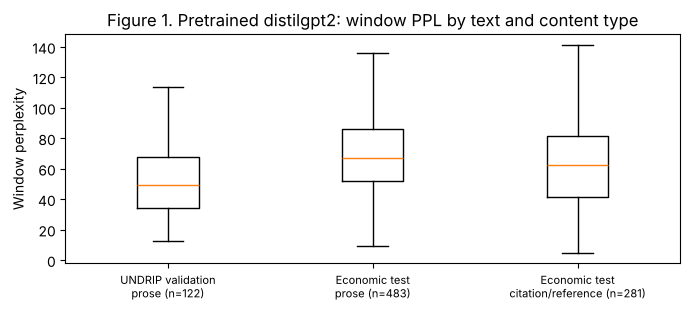

Highest-PPL Economic-test window (first 200 chars):
'\nCanberra\nTe Rūnanga o Ngāi Tahu\n- Mr Benjamin Bateman, Ng āi Tahu and Cook Island Māori —Chief Executive\nOfficer [video]'


In [11]:
# Investigation: which content does pretrained distilgpt2 find most surprising?
# Each 128-token evaluation window is labelled "citation/reference" if its text contains a
# citation marker (Submission N, Committee Hansard, p. N, URL), otherwise "prose".

def window_table(result):
    frame = pd.DataFrame({"window": result["window"], "nll": result["nll"], "token_id": result["token_ids"]})
    rows = []
    for window, group in frame.groupby("window"):
        text = tokenizer.decode(group["token_id"].tolist())
        rows.append({"window": window, "ppl": math.exp(group["nll"].mean()),
                     "type": "citation/reference" if CITATION_LINE.search(text) else "prose", "text": text})
    return pd.DataFrame(rows)

pretrained_windows = {name: window_table(result) for name, result in evaluations["Pretrained"].items()}

summary = []
for name, windows in pretrained_windows.items():
    for kind, group in windows.groupby("type"):
        summary.append({"Text": name, "Window type": kind, "Windows": len(group),
                        "Share of windows (%)": round(100 * len(group) / len(windows), 1),
                        "Median window PPL": round(group["ppl"].median(), 1)})
    summary.append({"Text": name, "Window type": "all", "Windows": len(windows), "Share of windows (%)": 100.0,
                    "Median window PPL": round(windows["ppl"].median(), 1)})
print("Table 2. Pretrained window-level perplexity by content type")
display(pd.DataFrame(summary))

# Newline tokens: the PDF keeps its hard line-wraps, so many "\n" tokens fall mid-sentence.
NEWLINE_ID = tokenizer("\n")["input_ids"][0]
for name, result in evaluations["Pretrained"].items():
    is_newline = result["token_ids"] == NEWLINE_ID
    print(f"{name:18s}: newline tokens = {100 * is_newline.mean():.1f}% of predicted tokens, "
          f"mean NLL {result['nll'][is_newline].mean():.2f} (other tokens {result['nll'][~is_newline].mean():.2f})")

# Controlled re-formatting (diagnostic only; the main results always use the unchanged files).
def without_citation_lines(text):
    return "\n".join(line for line in text.splitlines() if not CITATION_LINE.search(line))

variants = []
for name, text in eval_texts.items():
    for label, variant in [("as prepared", text),
                           ("newlines -> spaces", text.replace("\n", " ")),
                           ("citation lines removed", without_citation_lines(text)),
                           ("both", without_citation_lines(text).replace("\n", " "))]:
        ppl = evaluations["Pretrained"][name]["ppl"] if label == "as prepared" else evaluate_perplexity(pretrained_model, variant)["ppl"]
        variants.append({"Text": name, "Formatting": label, "Pretrained PPL": round(ppl, 2)})
print("\nTable 3. Pretrained PPL under controlled re-formatting of the evaluation texts")
display(pd.DataFrame(variants).pivot(index="Formatting", columns="Text", values="Pretrained PPL")
        .loc[["as prepared", "newlines -> spaces", "citation lines removed", "both"]])

fig, ax = plt.subplots(figsize=(7, 3.2))
labels_, data_ = [], []
for name, windows in pretrained_windows.items():
    for kind in ["prose", "citation/reference"]:
        selected = windows.loc[windows["type"] == kind, "ppl"]
        if len(selected):
            labels_.append(f"{name}\n{kind} (n={len(selected)})")
            data_.append(selected)
ax.boxplot(data_, showfliers=False)
ax.set_xticks(range(1, len(labels_) + 1), labels_, fontsize=8)
ax.set_ylabel("Window perplexity")
ax.set_title("Figure 1. Pretrained distilgpt2: window PPL by text and content type")
plt.tight_layout(); plt.show()

print("Highest-PPL Economic-test window (first 200 chars):")
print(repr(pretrained_windows["Economic test"].sort_values("ppl").iloc[-1]["text"][:200]))

## Independent Investigation of Data or Pretrained Model Behaviour

- Investigation question:
    How much of the pretrained perplexity gap between UNDRIP validation (53.23) and Economic test (62.62) comes from how the text was extracted (PDF footnotes and line-wraps) rather than from its content?

-  Analysis and findings:
    1. *Footnotes.* 36.8% of the Economic-test windows contain citation markers, while UNDRIP validation has none because Word footnotes were not extracted (Table 2). I expected these windows to be the hardest. Instead they are **easier** (median window PPL 62.6 vs 66.7 for prose, Figure 1), because footnotes are formulaic and repetitive ("Committee Hansard, Canberra, … p. 6"). Removing citation lines **raises** the Economic PPL to 68.98 (Table 3).
    2. *Line-wraps.* Newline tokens are cheap in UNDRIP validation (mean NLL 1.32, since they follow paragraph-ending full stops) but expensive in the Economic test (3.35, since they fall mid-sentence at PDF line-wraps). Replacing newlines with spaces lowers the Economic PPL to 56.93 but raises UNDRIP validation to 62.43, because the easy paragraph-break predictions disappear.
    3. *Both removed.* With both formatting effects removed, the two texts are almost equally hard (61.73 vs 62.43), so the gap disappears and slightly reverses.

    The 9.4-point baseline gap is therefore mostly an extraction effect, not evidence that economic content is harder for distilgpt2. The two PDF artefacts pull in opposite directions: footnotes lower PPL and mid-sentence line-breaks raise it.

-  Limitation or alternative explanation:
     Reformatting changes which tokens are scored, not only how hard they are, so the variants are not perfectly matched comparisons. The citation regex also misses some footnotes. Alternatively, equal PPL after reformatting could hide a harder topic offset by the Economic report's more repetitive committee phrasing.

# Task 2 Full fine-tuning (25%)

Fine-tune `distilgpt2` once using the fixed full fine-tuning configuration. Report the result in the master results table.


In [12]:
# Start full fine-tuning from a fresh pretrained model.
full_model = AutoModelForCausalLM.from_pretrained(BASE_MODEL)
full_model.resize_token_embeddings(len(tokenizer))
full_model.config.pad_token_id = tokenizer.pad_token_id

# Full fine-tuning code goes here.
# Use FULL_FINE_TUNING_CONFIG for the required main result.
# Keep the base model, tokenizer, training text, validation text, test text,
# evaluation metric, and generation prompt fixed.

def build_lm_dataset(path, block_size=TOKENISATION_CONFIG["block_size"]):
    """Tokenise a whole text file and cut it into contiguous block_size chunks (labels = input_ids)."""
    ids = tokenizer(Path(path).read_text(encoding="utf-8"))["input_ids"]
    n_blocks = len(ids) // block_size                     # drop the final partial block
    blocks = [ids[i * block_size:(i + 1) * block_size] for i in range(n_blocks)]
    return Dataset.from_dict({"input_ids": blocks,
                              "attention_mask": [[1] * block_size for _ in blocks],
                              "labels": [list(b) for b in blocks]})

train_dataset = build_lm_dataset(TEXT_FILES["train"])
print(f"Training blocks: {len(train_dataset)} x {TOKENISATION_CONFIG['block_size']} tokens")

def train_quietly(model, training_args, dataset):
    """Train with the Hugging Face Trainer; progress bars are removed to keep the exported PDF clean."""
    trainer = Trainer(model=model, args=training_args, train_dataset=dataset, data_collator=default_data_collator)
    for callback in list(trainer.callback_handler.callbacks):
        if type(callback).__name__ in {"ProgressCallback", "NotebookProgressCallback", "PrinterCallback"}:
            trainer.remove_callback(callback)
    start = time.perf_counter()
    trainer.train()
    minutes = (time.perf_counter() - start) / 60
    return trainer, minutes

full_training_args = TrainingArguments(**FULL_FINE_TUNING_CONFIG)
full_trainable = sum(p.numel() for p in full_model.parameters() if p.requires_grad)
full_trainer, full_minutes = train_quietly(full_model, full_training_args, train_dataset)
print(f"Parameters updated: {full_trainable:,} | training time: {full_minutes:.2f} min | "
      f"steps: {full_trainer.state.global_step}")

Training blocks: 488 x 128 tokens


Parameters updated: 81,912,576 | training time: 2.48 min | steps: 244


### Full fine-tuning investigation — prediction and rationale (recorded before evaluating the full fine-tuned model)

**Prediction.** (1) Full fine-tuning will lower PPL on both texts, but the relative drop on `undrip_val.txt` will be clearly larger than on `economic_test.txt`. (2) The gain will be concentrated on tokens that occur often in `undrip_train.txt` (committee-report register, *Aboriginal and Torres Strait Islander*, *UNDRIP*), while tokens rare in or absent from the training text will improve little.

**Rationale.** One epoch over ~62k tokens cannot teach general language, but it can raise the probability of phrases seen repeatedly, so training-text frequency should predict where the loss falls.

**Test.** Compare per-token NLL of the pretrained and full fine-tuned models on the same evaluation tokens, grouped by how often each target token occurs in the tokenised training text.

In [13]:
full_model.to(DEVICE)
evaluations["Full fine-tuned"] = {name: evaluate_perplexity(full_model, text) for name, text in eval_texts.items()}
master_results["Full fine-tuned distilgpt2"] = {
    "Parameters updated during adaptation": full_trainable,
    "Training time (min)": full_minutes,
    "PPL on UNDRIP validation": evaluations["Full fine-tuned"]["UNDRIP validation"]["ppl"],
    "PPL on Economic test": evaluations["Full fine-tuned"]["Economic test"]["ppl"],
}
for name in eval_texts:
    before, after_ = evaluations["Pretrained"][name]["ppl"], evaluations["Full fine-tuned"][name]["ppl"]
    print(f"{name:18s} | pretrained {before:7.2f} -> full fine-tuned {after_:7.2f}  ({100 * (after_ - before) / before:+.1f}%)")

UNDRIP validation  | pretrained   53.23 -> full fine-tuned   34.92  (-34.4%)
Economic test      | pretrained   62.62 -> full fine-tuned   50.92  (-18.7%)


## Task 2 evidence

Include either a training-loss curve or a compact final training-loss record.


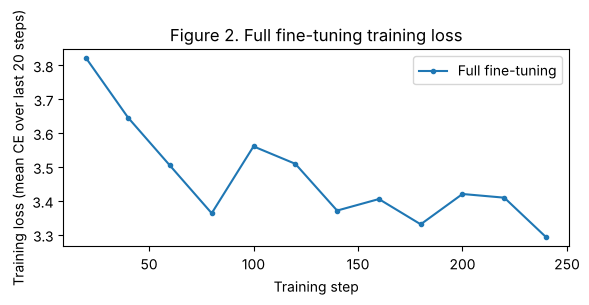

Compact training-loss record (full fine-tuning):
  first logged loss: 3.820 (step 20)
  final logged loss: 3.293 (step 240)
  mean training loss over the epoch: 3.470


In [14]:
# Training loss of the fixed full fine-tuning run (logged every 20 steps).
def loss_history(trainer):
    return pd.DataFrame([log for log in trainer.state.log_history if "loss" in log])[["step", "epoch", "loss"]]

full_loss = loss_history(full_trainer)
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(full_loss["step"], full_loss["loss"], marker="o", ms=3, label="Full fine-tuning")
ax.set_xlabel("Training step"); ax.set_ylabel("Training loss (mean CE over last 20 steps)")
ax.set_title("Figure 2. Full fine-tuning training loss"); ax.legend(); plt.tight_layout(); plt.show()

print("Compact training-loss record (full fine-tuning):")
print(f"  first logged loss: {full_loss['loss'].iloc[0]:.3f} (step {int(full_loss['step'].iloc[0])})")
print(f"  final logged loss: {full_loss['loss'].iloc[-1]:.3f} (step {int(full_loss['step'].iloc[-1])})")
print(f"  mean training loss over the epoch: {full_trainer.state.log_history[-1]['train_loss']:.3f}")

Table 4. Per-token NLL change (pretrained - full fine-tuned), by token frequency in undrip_train.txt


,Text,Train-frequency bin,Share of tokens (%),Mean NLL drop,Share of total NLL drop (%),Tokens that got worse (%)
0,UNDRIP validation,0 (unseen),6.3,-0.430,-6.4,75.5
1,UNDRIP validation,1-9,19.9,0.251,11.9,45.1
2,UNDRIP validation,10-99,28.0,0.810,53.8,27.9
3,UNDRIP validation,100-999,21.0,0.667,33.2,30.6
4,UNDRIP validation,>=1000,24.8,0.129,7.6,41.5
5,Economic test,0 (unseen),16.1,-0.440,-34.2,76.6
6,Economic test,1-9,23.3,0.287,32.3,49.4
7,Economic test,10-99,18.4,0.522,46.3,33.2
8,Economic test,100-999,18.3,0.561,49.6,31.9
9,Economic test,>=1000,24.0,0.051,5.9,48.7


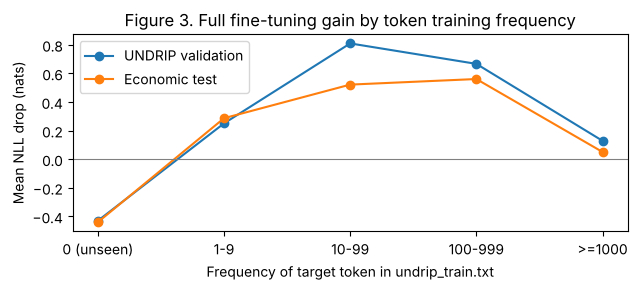

Economic test - tokens (>=30 occurrences) with the largest mean NLL drop:
                mean  count
' inquiry'      3.37     55
' Closing'      3.08     35
'Australian'    2.95     33
'development'   2.93     44
' highlighted'  2.61     33
'23'            2.59     88
'Recommend'     2.52     59
'�'             2.27    484

Economic test - tokens (>=30 occurrences) that got most worse:
            mean  count
' tourism' -2.03     45
' market'  -1.88     33
' economy' -1.66     53
' Clean'   -1.62     32
' Aust'    -1.60     41


In [15]:
# Investigation: where does the full fine-tuning gain come from?
train_token_counts = np.bincount(tokenizer(Path(TEXT_FILES["train"]).read_text(encoding="utf-8"))["input_ids"],
                                 minlength=len(tokenizer))
FREQ_BINS = [(0, 0, "0 (unseen)"), (1, 9, "1-9"), (10, 99, "10-99"), (100, 999, "100-999"), (1000, 10**9, ">=1000")]

def nll_change_by_frequency(model_name):
    rows = []
    for text_name in eval_texts:
        base, adapted = evaluations["Pretrained"][text_name], evaluations[model_name][text_name]
        freq = train_token_counts[base["token_ids"]]
        delta = base["nll"] - adapted["nll"]               # positive = adapted model is better
        total_gain = delta.sum()
        for low, high, label in FREQ_BINS:
            mask = (freq >= low) & (freq <= high)
            rows.append({"Text": text_name, "Train-frequency bin": label,
                         "Share of tokens (%)": round(float(100 * mask.mean()), 1),
                         "Mean NLL drop": round(float(delta[mask].mean()), 3),
                         "Share of total NLL drop (%)": round(float(100 * delta[mask].sum() / total_gain), 1),
                         "Tokens that got worse (%)": round(float(100 * (delta[mask] < 0).mean()), 1)})
    return pd.DataFrame(rows)

full_by_freq = nll_change_by_frequency("Full fine-tuned")
print("Table 4. Per-token NLL change (pretrained - full fine-tuned), by token frequency in undrip_train.txt")
display(full_by_freq)

fig, ax = plt.subplots(figsize=(6.5, 3))
for text_name, group in full_by_freq.groupby("Text", sort=False):
    ax.plot(group["Train-frequency bin"], group["Mean NLL drop"], marker="o", label=text_name)
ax.axhline(0, color="grey", lw=0.8)
ax.set_xlabel("Frequency of target token in undrip_train.txt"); ax.set_ylabel("Mean NLL drop (nats)")
ax.set_title("Figure 3. Full fine-tuning gain by token training frequency"); ax.legend(); plt.tight_layout(); plt.show()

# Largest per-word-piece improvements and degradations on the Economic test text
base, full = evaluations["Pretrained"]["Economic test"], evaluations["Full fine-tuned"]["Economic test"]
by_token = pd.DataFrame({"token": base["token_ids"], "delta": base["nll"] - full["nll"]}).groupby("token")["delta"].agg(["mean", "count"])
by_token = by_token[by_token["count"] >= 30]
by_token.index = [repr(tokenizer.decode([t])) for t in by_token.index]
print("Economic test - tokens (>=30 occurrences) with the largest mean NLL drop:")
print(by_token.sort_values("mean", ascending=False).head(8).round(2).to_string())
print("\nEconomic test - tokens (>=30 occurrences) that got most worse:")
print(by_token.sort_values("mean").head(5).round(2).to_string())

**Investigation and supporting evidence.**

- *Prediction (1): supported.* UNDRIP validation PPL fell from 53.23 to 34.92 (−34.4%), but Economic test PPL only from 62.62 to 50.92 (−18.7%).
- *Prediction (2): partly supported.* Tokens seen 10–999 times in training supply 87% (val) and 96% (test) of the total NLL reduction (Table 4, Figure 3). The most improved Economic-test tokens are report register: ` inquiry` (−3.37 nats), ` Closing` (Closing the Gap), `Recommend`. The relationship is not monotonic, though. The most frequent tokens (≥1000: function words and punctuation) improved little (0.13 / 0.05 nats), because the pretrained model already predicts them well.

**Unexpected observation.** Tokens **never seen in training got worse** (−0.43 val, −0.44 test, with ~76% of them degraded). They make up 16.1% of Economic-test tokens and cancel 34.2% of its gain. The worst-hit tokens are economic vocabulary: ` tourism` (+2.03 nats), ` market`, ` economy`. Within 244 steps, full fine-tuning shifts probability mass away from words the training text lacks. This narrowing helps explain why transfer is about half the in-domain gain.

**Limitation.** Unseen tokens are also rarer in general, so part of their degradation may reflect rarity rather than absence from training. This is also a single run with one seed, so there is no estimate of variance.

# Task 3 LoRA adaptation and comparison (25%)

Train a LoRA-adapted version of `distilgpt2` using the fixed LoRA configuration. Reload a fresh distilgpt2 base model before applying LoRA. Do not apply LoRA to the full fine-tuned model from Task 2.
Report the result in the master results table.


LoRA trainable parameters: 147,456 of 82,060,032 (0.180%)


LoRA training time: 1.24 min | steps: 244


Table 5. Master results table (code-generated; copied into the markdown table in Task 1)


,Parameters updated during adaptation,Training time (min),PPL on UNDRIP validation,PPL on Economic test
Pretrained distilgpt2,0,0.00,53.23,62.62
Full fine-tuned distilgpt2,"81,912,576",2.48,34.92,50.92
LoRA-adapted distilgpt2,"147,456",1.24,48.18,56.68


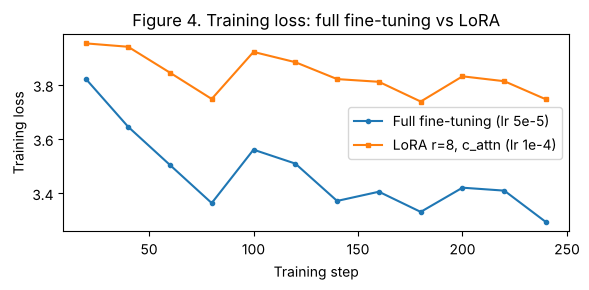

LoRA training loss: first logged 3.953, final logged 3.747, epoch mean 3.840


In [16]:
# Start LoRA from a fresh pretrained model, not from the full fine-tuned model.
lora_base_model = AutoModelForCausalLM.from_pretrained(BASE_MODEL)
lora_base_model.resize_token_embeddings(len(tokenizer))
lora_base_model.config.pad_token_id = tokenizer.pad_token_id

# LoRA adaptation and evaluation code goes here.
# Use LORA_CONFIG for the required main result.
lora_training_args = TrainingArguments(**LORA_TRAINING_CONFIG)
# Apply LoRA to lora_base_model and store the adapted model as lora_model.
# Do not apply LoRA on top of the full fine-tuned model for the required comparison.
transformers.set_seed(SEED)                       # same seed for the LoRA initialisation
lora_model = get_peft_model(lora_base_model, LoraConfig(**LORA_CONFIG))
lora_trainable = sum(p.numel() for p in lora_model.parameters() if p.requires_grad)
lora_total = sum(p.numel() for p in lora_model.parameters())
print(f"LoRA trainable parameters: {lora_trainable:,} of {lora_total:,} ({100 * lora_trainable / lora_total:.3f}%)")

lora_trainer, lora_minutes = train_quietly(lora_model, lora_training_args, train_dataset)
print(f"LoRA training time: {lora_minutes:.2f} min | steps: {lora_trainer.state.global_step}")

lora_model.to(DEVICE)
evaluations["LoRA"] = {name: evaluate_perplexity(lora_model, text) for name, text in eval_texts.items()}
master_results["LoRA-adapted distilgpt2"] = {
    "Parameters updated during adaptation": lora_trainable,
    "Training time (min)": lora_minutes,
    "PPL on UNDRIP validation": evaluations["LoRA"]["UNDRIP validation"]["ppl"],
    "PPL on Economic test": evaluations["LoRA"]["Economic test"]["ppl"],
}

master_table = pd.DataFrame(master_results).T
master_table["Training time (min)"] = master_table["Training time (min)"].round(2)
master_table[["PPL on UNDRIP validation", "PPL on Economic test"]] = master_table[["PPL on UNDRIP validation", "PPL on Economic test"]].round(2)
master_table["Parameters updated during adaptation"] = master_table["Parameters updated during adaptation"].astype(int).map("{:,}".format)
print("Table 5. Master results table (code-generated; copied into the markdown table in Task 1)")
display(master_table)

fig, ax = plt.subplots(figsize=(6, 3))
lora_loss = loss_history(lora_trainer)
ax.plot(full_loss["step"], full_loss["loss"], marker="o", ms=3, label="Full fine-tuning (lr 5e-5)")
ax.plot(lora_loss["step"], lora_loss["loss"], marker="s", ms=3, label="LoRA r=8, c_attn (lr 1e-4)")
ax.set_xlabel("Training step"); ax.set_ylabel("Training loss")
ax.set_title("Figure 4. Training loss: full fine-tuning vs LoRA"); ax.legend(); plt.tight_layout(); plt.show()
print(f"LoRA training loss: first logged {lora_loss['loss'].iloc[0]:.3f}, final logged {lora_loss['loss'].iloc[-1]:.3f}, "
      f"epoch mean {lora_trainer.state.log_history[-1]['train_loss']:.3f}")

## Generation comparison table

Use the fixed generation prompt exactly. Keep outputs short enough to be readable in the exported PDF.

Table B. Greedy continuations (`max_new_tokens=80`, `do_sample=False`). The full outputs are printed by the next cell, and "…" marks where an output repeats the previous sentence until the 80-token limit.

| Prompt | Pretrained output | Full fine-tuned output | LoRA-adapted output | One-sentence comparison |
|---|---|---|---|---|
| `Economic self-determination for First Nations peoples requires` | "a strong commitment to the rights of all peoples." followed by 70 newline tokens | "a national government to implement the Declaration. The Declaration is a declaration of the rights of First Peoples to self-determination for First Peoples." (this last sentence then repeats 3 more times) … | "a comprehensive and comprehensive international framework for the development of the peoples of the world. The UN Declaration on the Rights of Indigenous Peoples states: The right of the peoples to self-determination for the peoples of the world is enshrined in the Declaration of the Rights of Indigenous Peoples." (then repeats) … | Adaptation moves the continuation from generic rights language to UNDRIP vocabulary ("implement the Declaration", "First Peoples"), most strongly for full fine-tuning, but greedy decoding makes both adapted models loop (distinct-trigram ratio 0.36 full vs 0.68 LoRA), and none of the three says anything economic. |

In [17]:
# Generation code for pretrained_model, full_model, and lora_model goes here.
# Use GENERATION_PROMPT and GENERATION_CONFIG for the required comparison (greedy decoding, 80 new tokens).

@torch.no_grad()
def generate_continuation(model, prompt=GENERATION_PROMPT):
    model.eval()
    inputs = tokenizer(prompt, return_tensors="pt").to(DEVICE)
    output_ids = model.generate(**inputs, **GENERATION_CONFIG, pad_token_id=tokenizer.pad_token_id)
    return tokenizer.decode(output_ids[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True)

def distinct_ratio(text, n=3):
    words = text.split()
    ngrams = [tuple(words[i:i + n]) for i in range(len(words) - n + 1)]
    return len(set(ngrams)) / max(1, len(ngrams))

generations = {name: generate_continuation(model) for name, model in
               [("Pretrained", pretrained_model), ("Full fine-tuned", full_model), ("LoRA", lora_model)]}
for name, continuation in generations.items():
    shown = continuation.rstrip()
    trailing_newlines = continuation[len(shown):].count("\n")
    print(f"[{name}] distinct word-trigram ratio = {distinct_ratio(continuation):.2f}")
    print(f"{GENERATION_PROMPT}{shown}")
    if trailing_newlines:
        print(f"[... followed by {trailing_newlines} newline tokens until the 80-token limit; omitted here]")
    print()

[Pretrained] distinct word-trigram ratio = 1.00
Economic self-determination for First Nations peoples requires a strong commitment to the rights of all peoples.
[... followed by 70 newline tokens until the 80-token limit; omitted here]

[Full fine-tuned] distinct word-trigram ratio = 0.36
Economic self-determination for First Nations peoples requires a national government to implement the Declaration.
The Declaration is a declaration of the rights of First Peoples to self-determination for First Peoples.
The Declaration is a declaration of the rights of First Peoples to self-determination for First Peoples.
The Declaration is a declaration of the rights of First Peoples to self-determination for First Peoples.
The Declaration is a declaration of the rights of First Peoples

[LoRA] distinct word-trigram ratio = 0.68
Economic self-determination for First Nations peoples requires a comprehensive and comprehensive international framework for the development of the peoples of the world.

Th

In [18]:
# LoRA behaviour investigation: where does LoRA fall short of full fine-tuning?
lora_by_freq = nll_change_by_frequency("LoRA")
comparison = full_by_freq[["Text", "Train-frequency bin", "Share of tokens (%)"]].copy()
comparison["Full FT mean NLL drop"] = full_by_freq["Mean NLL drop"]
comparison["LoRA mean NLL drop"] = lora_by_freq["Mean NLL drop"]
comparison["LoRA recovery (%)"] = (100 * comparison["LoRA mean NLL drop"] / comparison["Full FT mean NLL drop"]).astype(float).round(1)
print("Table 6. Mean per-token NLL drop vs pretrained, full fine-tuning vs LoRA, by token frequency in undrip_train.txt")
display(comparison)

for text_name in eval_texts:
    base = evaluations["Pretrained"][text_name]["nll"].mean()
    full_gain = base - evaluations["Full fine-tuned"][text_name]["nll"].mean()
    lora_gain = base - evaluations["LoRA"][text_name]["nll"].mean()
    print(f"{text_name:18s}: LoRA recovers {100 * lora_gain / full_gain:.1f}% of the full fine-tuning NLL reduction")

# Is LoRA still learning at the end of its single epoch? Compare the slope of the last logged losses.
tail = lambda frame: np.polyfit(frame["step"].tail(5), frame["loss"].tail(5), 1)[0] * 100
print(f"\nSlope of training loss over the last 5 logs (per 100 steps): full {tail(full_loss):+.3f}, LoRA {tail(lora_loss):+.3f}")

# Window-level: on how many evaluation windows is LoRA closer to the pretrained model than to full fine-tuning?
for text_name in eval_texts:
    frame = pd.DataFrame({"w": evaluations["Pretrained"][text_name]["window"],
                          "pre": evaluations["Pretrained"][text_name]["nll"],
                          "full": evaluations["Full fine-tuned"][text_name]["nll"],
                          "lora": evaluations["LoRA"][text_name]["nll"]}).groupby("w").mean()
    closer_to_pre = ((frame["lora"] - frame["pre"]).abs() < (frame["lora"] - frame["full"]).abs()).mean()
    print(f"{text_name:18s}: LoRA window NLL closer to pretrained than to full FT in {100 * closer_to_pre:.1f}% of windows")

Table 6. Mean per-token NLL drop vs pretrained, full fine-tuning vs LoRA, by token frequency in undrip_train.txt


,Text,Train-frequency bin,Share of tokens (%),Full FT mean NLL drop,LoRA mean NLL drop,LoRA recovery (%)
0,UNDRIP validation,0 (unseen),6.3,-0.430,-0.015,3.5
1,UNDRIP validation,1-9,19.9,0.251,0.074,29.5
2,UNDRIP validation,10-99,28.0,0.810,0.146,18.0
3,UNDRIP validation,100-999,21.0,0.667,0.178,26.7
4,UNDRIP validation,>=1000,24.8,0.129,0.031,24.0
5,Economic test,0 (unseen),16.1,-0.440,0.008,-1.8
6,Economic test,1-9,23.3,0.287,0.124,43.2
7,Economic test,10-99,18.4,0.522,0.146,28.0
8,Economic test,100-999,18.3,0.561,0.171,30.5
9,Economic test,>=1000,24.0,0.051,0.047,92.2


UNDRIP validation : LoRA recovers 23.6% of the full fine-tuning NLL reduction
Economic test     : LoRA recovers 48.2% of the full fine-tuning NLL reduction

Slope of training loss over the last 5 logs (per 100 steps): full -0.073, LoRA -0.027
UNDRIP validation : LoRA window NLL closer to pretrained than to full FT in 90.2% of windows
Economic test     : LoRA window NLL closer to pretrained than to full FT in 54.5% of windows


### LoRA behaviour investigation

**Unexpected or weaker behaviour.** I expected LoRA to recover most of full fine-tuning's gain on the training-like UNDRIP validation text, since the LoRA paper reports near-parity. Instead, LoRA lowered validation PPL only from 53.23 to **48.18** (full fine-tuning: 34.92), which is **23.6%** of full fine-tuning's NLL reduction, compared with 48.2% on the Economic test. LoRA was weakest exactly where adaptation should be easiest.

**Investigation and supporting evidence.**
- *Token level (Table 6).* On validation, LoRA recovers only **18%** of the gain on tokens seen 10–99 times in training, the domain-vocabulary bin that drove full fine-tuning. Also, **90.2%** of validation windows are closer to the pretrained model than to the full fine-tuned model.
- *Training dynamics (Figure 4).* LoRA's training loss fell only from 3.953 to 3.747 (full fine-tuning: 3.820 → 3.293) and was still falling at the end of the epoch (−0.027 per 100 steps). The adapter was under-fitted, not converged.
- *Why transfer looks better.* LoRA barely changes tokens unseen in training (−0.015 / +0.008 nats, against −0.43 / −0.44 for full fine-tuning). It avoids the narrowing that ate a third of full fine-tuning's Economic-test gain, so its higher "recovery" there reflects less damage, not more learning.

**Explanation and limitation.** The fixed configuration trains 147,456 parameters (0.18%), a rank-8 update to the `c_attn` query/key/value projection only. Raising the probability of report vocabulary (` inquiry`, ` Closing`) means changing the token-level output distribution, which in GPT-2 is shaped largely by the MLP blocks and the tied embedding/LM head, and LoRA leaves those frozen. Also, LoRA's `B` matrix starts at zero, so with lr 1e-4 and 244 steps the update stays small. **Limitation:** I cannot separate these causes (target modules and rank versus step budget) without extra runs that the fixed protocol excludes, and the claim about where lexical knowledge is stored was not tested here.

# Task 4 Interpretation and learning reflection (20%)

This task is about explanation and evidence of your individual learning.


## Task 4A Technical interpretation (15%)

Answer the following questions in at most **300 words** total. Your answers must refer to your own master results table and generation comparison table.

1. Using your reported perplexity values, what do your results show about adaptation to `undrip_val.txt` versus transfer to `economic_test.txt`? what is one conclusion that cannot be made from perplexity alone?
2. Using your reported trainable-parameter count, training time, perplexity values, and generation comparison, and findings from Task 2 and Task 3, what trade-off do you observe between full fine-tuning and LoRA? identify and explain one result that supports the overall pattern and one result that does not.
3. Suppose you could retain only one adapted model for future use under limited computational resources. Which would you retain: full fine-tuning or LoRA? Defend your decision using your own experimental evidence, and identify one piece of evidence from your results that challenges your choice. 
 

Before writing, look at your master results table and generation comparison table. Your discussion should refer to your own reported values. For example: "Full fine-tuning reduced PPL on UNDRIP validation from X to Y, while LoRA reduced it to Z."

**Your response:**

**1. Adaptation vs transfer.** Full fine-tuning reduced PPL on `undrip_val.txt` from 53.23 to 34.92 (−34%), but on `economic_test.txt` only from 62.62 to 50.92 (−19%). LoRA reduced them to 48.18 (−9%) and 56.68 (−9%). Both models adapted in-domain, but only part of the gain transfers to the related report, and Task 2 showed that full fine-tuning's transfer is held back by economic words (` tourism`, ` economy`) getting *worse*. Perplexity alone cannot show whether generated text is better: full fine-tuning has the lowest PPL yet the most repetitive generation (distinct-trigram ratio 0.36), looping on "The Declaration is a declaration of the rights of First Peoples…".

**2. Trade-off.** LoRA updated 147,456 parameters (0.18% of 81.9M) and trained in 1.24 instead of 2.48 minutes, but recovered only 24% (validation) and 48% (test) of full fine-tuning's NLL reduction. *Supports the pattern:* lower cost bought a smaller in-domain gain (48.18 vs 34.92), and Table 6 shows LoRA lagging most on mid-frequency domain tokens. *Does not fit:* LoRA was not simply a weaker full fine-tune. It left unseen-token NLL almost unchanged (−0.015 vs −0.43 nats) and generated less repetitive text (0.68). In addition, 555× fewer trainable parameters bought only a 2.0× speed-up, because the forward and backward passes through the frozen network still dominate.

**3. Choice.** Under limited compute I would keep **LoRA**. It stores 147k parameters (~0.6 MB) instead of an 82M-parameter (~330 MB) copy, trains in half the time, keeps the base model's behaviour on unseen vocabulary, and several adapters can share one base model. *Challenging evidence:* full fine-tuning's in-domain PPL (34.92) is far better than LoRA's (48.18), and LoRA recovered only 24% of that gain. If UNDRIP-domain fit were the only goal, full fine-tuning would win.


## Task 4B Learning reflection (5%)

Answer the following question in at most **200** words.
Select one specific moment from a lecture recording in Weeks 5 –11 that changed, challenged, or clarified your understanding of a deep learning concept. Identify the week and approximate timestamp of the selected moment and briefly state the concept being discussed.

Explain:
    - what you understood or assumed about the concept before watching this part of the lecture;
    - what specifically in the selected lecture segment changed, challenged, or clarified your thinking;
    - what you understand differently now; and
    - how this understanding would influence the way you approach a future deep learning problem.

**Your response:**  
[Replace. This must be your own reflection on a specific moment in a Week 5–11 lecture recording that you watched (week, approximate timestamp, concept). Cover what you assumed before, what in that segment changed or clarified your thinking, what you understand now, and how it would change your approach to a future problem. Maximum 200 words.]


# Final checklist

- [ ] The notebook filename follows the required format. *(rename to `[YourID]_SIT744_assignment4_solution.ipynb`)*
- [ ] The PDF export filename follows the required format. *(`[YourID]_SIT744_assignment4_output.pdf`)*
- [x] `undrip_train.txt`, `undrip_val.txt`, and `economic_test.txt` are submitted.
- [x] The 80/20 UNDRIP split is followed.
- [x] All modelling tasks use the text files created in Task 1.
- [x] The data-preparation table is completed.
- [x] The master results table is completed.
- [x] A training-loss curve or compact final training-loss record is included.
- [x] The generation comparison table is completed.
- [x] The fixed generation prompt is used exactly.
- [x] Perplexity is reported consistently.
- [x] The technical interpretation is concise.
- [x] My technical interpretation refers to my own master results table and generation comparison table.
- [ ] The learning reflection identifies a concrete change in understanding. *(Task 4B still to be written)*
- [x] Code outputs are cleaned before PDF export.
- [ ] Cloud resources are shut down after use.